# Game state and team background features

Stage 02 constructs **pre-delivery** features for every recorded event. The label is **the first-innings batting team wins** for both innings. No models are trained here.

Inputs: the verified Stage 01 clean export. Outputs: `data/processed/game_state/` and `outputs/02_game_state_features/`.

Set `RUN_STAGE = True` to rebuild. With `False`, only verified existing outputs are read; stale or missing outputs stop with instructions, never trigger an automatic rebuild. Saving figures does not rebuild the feature dataset.

In [10]:
from pathlib import Path
import importlib
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / 'src' / 'game_state_features.py').is_file()
             and (p / 'config' / 'game_state.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook inside the project directory.')
sys.path.insert(0, str(ROOT / 'src'))
import game_state_features as stage
import game_state_visualisation as viz
from audit_visualisation import table
importlib.reload(stage)
importlib.reload(viz)

RUN_STAGE = False
SAVE_FIGURES = True
EXAMPLE_MATCH_ID = None  # None selects the median-length match, not a favourable model result.
OUTPUT = ROOT / stage.REPORT_DIR
DATA = ROOT / stage.DATA_DIR
print('Project:', ROOT)
print('Python:', sys.executable)
print('pandas:', pd.__version__)


Project: D:\T20_Project\T20_Project_3.0
Python: d:\T20_Project\T20_Project_3.0\.venv\Scripts\python.exe
pandas: 2.3.3


## 1. Build or verify the feature export

The source manifests and files are checked using SHA-256. Stage 01 is not rerun. The cohort and event count must be preserved exactly.

In [11]:
if RUN_STAGE:
    stage.run(ROOT)
summary = stage.verified_output(ROOT)
features = pd.read_csv(DATA / 'game_state_features.csv.gz', parse_dates=['match_date'], low_memory=False)
background = pd.read_csv(DATA / 'match_background.csv', parse_dates=['match_date'])
coverage = pd.read_csv(OUTPUT / 'phase_coverage.csv')
contract = json.loads((OUTPUT / 'feature_contract.json').read_text(encoding='utf-8'))
dictionary = pd.read_csv(OUTPUT / 'feature_dictionary.csv')
checks = stage.validate_features(features, background, summary['events'])
print('Verified feature export:', summary['feature_id'])
print('Upstream Stage 01 audit:', summary['upstream_audit_id'])
display(table(pd.DataFrame([{'Check': key, 'Passed': value} for key, value in checks.items()]), 'Data checks', collapsed=True))


Verified feature export: 23d7cb39fed6eba6d52f75750e6d53a37ffe8aaac2c4f86b376f85e0b905631c
Upstream Stage 01 audit: 69804d9698fb8c81c6c47d3965c293fcef455d7fbe16e9c187574b0e8496b99f


Check,Passed
one_row_per_source_event,True
same_match_cohort,True
two_innings_per_match,True
fixed_binary_target,True
first_innings_chase_fields_absent,True
second_innings_chase_fields_present,True
no_missing_common_features,True
finite_numeric_features,True
valid_wickets,True
nonnegative_score_and_slots,True


## 2. Cohort and innings phases

Powerplay = observed overs 1-6; middle = 7-15; death = 16-20. The middle/death boundary is an analysis convention. All events, including wides/no-balls, retain their own rows.

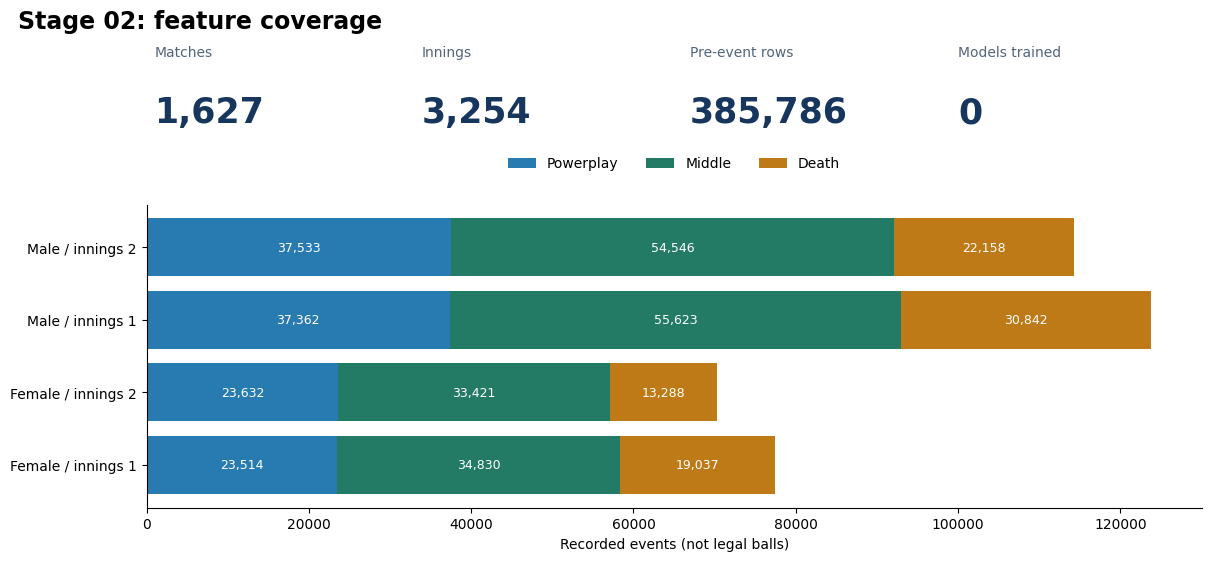

gender,match_innings,innings_phase,events,matches
female,1,death,19037,626
female,1,middle,34830,627
female,1,powerplay,23514,627
female,2,death,13288,544
female,2,middle,33421,625
female,2,powerplay,23632,627
male,1,death,30842,994
male,1,middle,55623,1000
male,1,powerplay,37362,1000
male,2,death,22158,905


In [12]:
saved_figures = []
def show_figure(fig, name):
    if SAVE_FIGURES:
        folder = OUTPUT / 'figures'
        folder.mkdir(parents=True, exist_ok=True)
        fig.savefig(folder / (name + '.png'), dpi=150, facecolor='white')
        saved_figures.append(name + '.png')
    display(fig)
    plt.close(fig)

show_figure(viz.overview_figure(summary, coverage), 'feature_coverage')
display(table(coverage, 'Exact phase coverage', collapsed=True))


## 3. What is eligible for the model?

The feature contract is an explicit allowlist, not an automatic selection of all numeric columns. The target, current-event outcomes, final results, actors and audit columns are not baseline predictors.

- Base: live state, phase, toss, long-term and recent team rates.
- Optional: team identity; previous-10-event runs and dismissals. These columns are retained for inspection but are not inputs to the current Stage 06-08 experiments. The common background is fixed across resource comparisons.
- Stage 03 builds player quality; Stage 04 builds dynamic availability; Stage 05 combines remaining resources.

`wickets_remaining` means **10 minus dismissals**, not the number of fit/available players. `toss_elected_bat` is retained for inspection but omitted from the base list because it duplicates `toss_first_team_won` in this cohort.

In [13]:
groups = [
    {'Block': 'Base numeric', 'Columns': ', '.join(contract['base_numeric'])},
    {'Block': 'Base categorical', 'Columns': ', '.join(contract['base_categorical'])},
    {'Block': 'Optional team identity', 'Columns': ', '.join(contract['optional_team_identity'])},
    {'Block': 'Optional recent events', 'Columns': ', '.join(contract['optional_recent_events'])},
    {'Block': 'Label, never a predictor', 'Columns': contract['target']},
]
display(table(pd.DataFrame(groups), 'Feature blocks'))
display(table(dictionary, 'Full feature dictionary and missing-value counts', collapsed=True))


Block,Columns
Base numeric,"match_innings, pre_score, wickets_remaining, scheduled_balls_remaining_estimate, current_run_rate, no_legal_ball_yet, target_runs, runs_required, required_run_rate, run_rate_differential, toss_first_team_won, first_team_prior_win_rate, second_team_prior_win_rate, first_team_recent_win_rate, second_team_recent_win_rate"
Base categorical,innings_phase
Optional team identity,"first_batting_team, second_batting_team"
Optional recent events,"runs_prev_10_events, wickets_prev_10_events"
"Label, never a predictor",first_batting_team_win


feature,role,definition,missing_rows,dtype
match_id,identifier_or_diagnostic,Identifier / diagnostic only; excluded from the default model feature list.,0,int64
source_row,identifier_or_diagnostic,Identifier / diagnostic only; excluded from the default model feature list.,0,int64
match_innings,base_numeric,Innings indicator (1 or 2); target perspective does not change.,0,int64
event_sequence,identifier_or_diagnostic,Identifier / diagnostic only; excluded from the default model feature list.,0,int64
batting_team,identifier_or_diagnostic,Identifier / diagnostic only; excluded from the default model feature list.,0,object
bowling_team,identifier_or_diagnostic,Identifier / diagnostic only; excluded from the default model feature list.,0,object
striker,identifier_or_diagnostic,Identifier / diagnostic only; excluded from the default model feature list.,0,object
non_striker,identifier_or_diagnostic,Identifier / diagnostic only; excluded from the default model feature list.,0,object
bowler,identifier_or_diagnostic,Identifier / diagnostic only; excluded from the default model feature list.,0,object
match_date,identifier_or_diagnostic,Identifier / diagnostic only; excluded from the default model feature list.,0,datetime64[ns]


## 4. Follow one match through both innings

Every point is the state **before** its recorded event. A dismissal changes wickets and the recent-event window from the next event onward. These are feature diagnostics, not predicted win probabilities; no terminal post-event point is appended.

The target label always refers to the first-innings batting team. Converting its probability to the current batting team's perspective would use p in innings 1 and 1-p in innings 2.

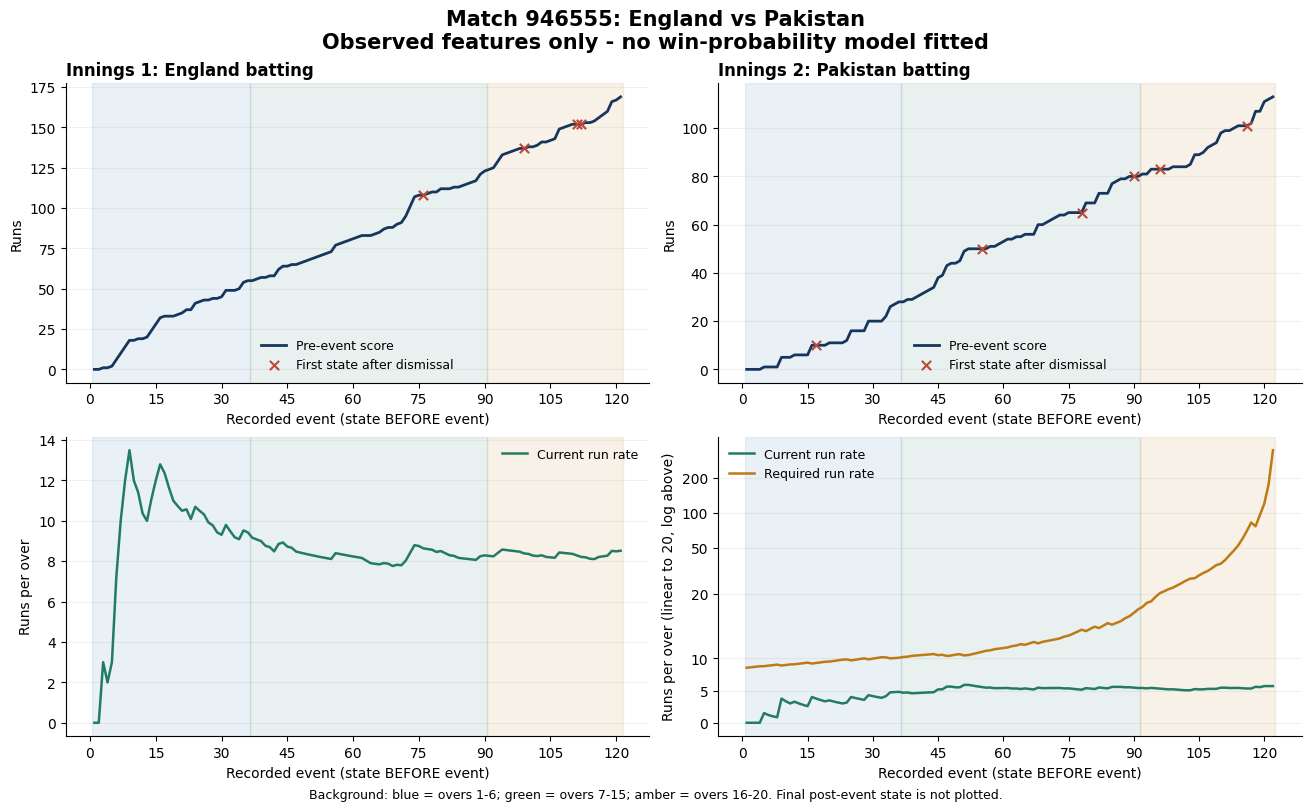

match_id,match_innings,event_sequence,batting_team,pre_score,pre_wickets,legal_balls_elapsed,scheduled_balls_remaining_estimate,innings_phase,runs_required,first_batting_team_win
946555,1,1,England,0,0,0,120,powerplay,Not available,1
946555,1,2,England,0,0,1,119,powerplay,Not available,1
946555,1,3,England,1,0,2,118,powerplay,Not available,1
946555,1,4,England,1,0,3,117,powerplay,Not available,1
946555,1,5,England,2,0,4,116,powerplay,Not available,1
946555,1,6,England,6,0,5,115,powerplay,Not available,1
946555,2,1,Pakistan,0,0,0,120,powerplay,171.0,1
946555,2,2,Pakistan,0,0,1,119,powerplay,171.0,1
946555,2,3,Pakistan,0,0,2,118,powerplay,171.0,1
946555,2,4,Pakistan,0,0,3,117,powerplay,171.0,1


In [14]:
example_id = viz.choose_example(features) if EXAMPLE_MATCH_ID is None else int(EXAMPLE_MATCH_ID)
example = features.loc[features.match_id.eq(example_id)].sort_values(['match_innings', 'event_sequence'])
if example.empty:
    raise ValueError('EXAMPLE_MATCH_ID is not in the clean cohort.')
show_figure(viz.match_figure(features, example_id), 'example_pre_delivery_states')
display(table(example[['match_id', 'match_innings', 'event_sequence', 'batting_team', 'pre_score',
                       'pre_wickets', 'legal_balls_elapsed', 'scheduled_balls_remaining_estimate',
                       'innings_phase', 'runs_required', stage.TARGET]].groupby('match_innings').head(6),
              'First six pre-event states of each innings', collapsed=True))


## 5. Long-term and recent team background

History is grouped by gender and uses only the retained Stage 01 cohort. All matches on the same date read the same prior history, then their results update later dates.

Long-term rate = (prior wins + 1)/(prior matches + 2). Recent rate uses decayed win/count totals with the same pseudo-counts; the default half-life is **10 matches**. Older evidence halves in weight after 10 further team matches. Matches on the same date have equal weight. Unseen teams start at 0.5, with prior exposure recorded separately.

This is distinct from the **10-event** within-innings window. These rates are descriptive historical features, not calibrated live predictions. In later evaluation, earlier completed holdout matches may update history for later dates under an explicitly rolling-origin protocol; model fitting still uses training data only.

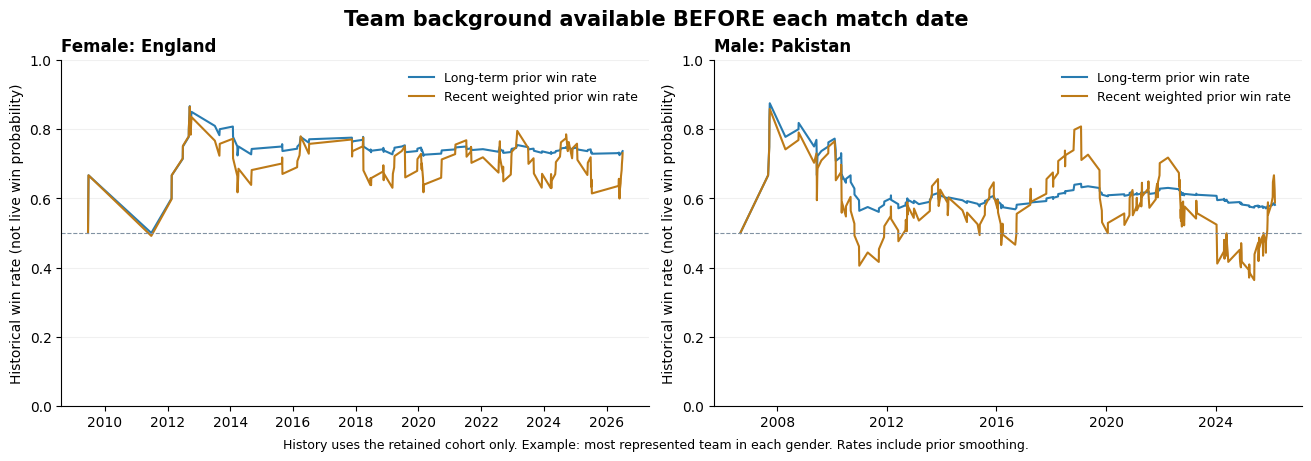

match_id,match_date,gender,first_batting_team,second_batting_team,first_team_prior_matches,first_team_prior_win_rate,first_team_recent_win_rate,second_team_prior_matches,second_team_prior_win_rate,second_team_recent_win_rate
211048,2005-02-17,male,Australia,New Zealand,0,0.500000,0.500000,0,0.500000,0.500000
211028,2005-06-13,male,England,Australia,0,0.500000,0.500000,1,0.666667,0.666667
222678,2005-10-21,male,South Africa,New Zealand,0,0.500000,0.500000,1,0.333333,0.333333
226374,2006-01-09,male,Australia,South Africa,2,0.500000,0.491487,1,0.333333,0.333333
238195,2006-02-24,male,South Africa,Australia,2,0.250000,0.254257,3,0.600000,0.597585
225271,2006-06-15,male,Sri Lanka,England,0,0.500000,0.500000,1,0.666667,0.666667
225263,2006-08-28,male,England,Pakistan,2,0.500000,0.491487,0,0.500000,0.500000
255954,2006-12-01,male,South Africa,India,3,0.400000,0.416356,0,0.500000,0.500000
251488,2006-12-26,male,Sri Lanka,New Zealand,1,0.666667,0.666667,2,0.500000,0.508513
249227,2007-01-09,male,Australia,England,4,0.500000,0.488847,3,0.400000,0.389407


In [15]:
show_figure(viz.history_figure(background), 'team_history')
display(table(background[['match_id', 'match_date', 'gender', 'first_batting_team', 'second_batting_team',
                          'first_team_prior_matches', 'first_team_prior_win_rate', 'first_team_recent_win_rate',
                          'second_team_prior_matches', 'second_team_prior_win_rate', 'second_team_recent_win_rate']].head(15),
              'Prior-date background examples', collapsed=True))


## 6. Inspect the optional recent-event window

For event t, sum at most the previous 10 recorded events in the same innings, excluding t. Runs include extras; temporary retirement does not count as a wicket. Wides/no-balls occupy window positions. Short opening windows use the available events; the first event has zeros.

These columns are retained for diagnostic inspection only. They are not inputs to the current Stage 06-08 experiments, and their add/remove comparison has not been performed.

In [16]:
display(table(example[['match_innings', 'event_sequence', 'pre_score', 'pre_wickets',
                       'audit_recent_window_events', 'runs_prev_10_events', 'wickets_prev_10_events',
                       'audit_runs_total', 'audit_wicket_count']].groupby('match_innings').head(14),
              'Past-window values versus current-event outcomes (audit columns only)'))


match_innings,event_sequence,pre_score,pre_wickets,audit_recent_window_events,runs_prev_10_events,wickets_prev_10_events,audit_runs_total,audit_wicket_count
1,1,0,0,0,0,0,0,0
1,2,0,0,1,0,0,1,0
1,3,1,0,2,1,0,0,0
1,4,1,0,3,1,0,1,0
1,5,2,0,4,2,0,4,0
1,6,6,0,5,6,0,4,0
1,7,10,0,6,10,0,4,0
1,8,14,0,7,14,0,4,0
1,9,18,0,8,18,0,0,0
1,10,18,0,9,18,0,1,0


## 7. Chase-only fields and exceptional clocks

Target, runs required, required rate and rate differential are NA in innings 1. A first-innings model must omit them; a unified model needs an innings-aware representation and training-only preprocessing in Stage 06.

Remaining scheduled slots are estimated from the **observed over** and already completed legal deliveries within it, not from future miscount metadata or final innings length. If six legal deliveries have already occurred in an over, its nominal remaining slots are zero until the observed next over. A zero total rate denominator is floored to one and flagged, never silently treated as a known final-ball count.

Before any legal delivery, current run rate is zero by convention and `no_legal_ball_yet` flags it. Pre-innings penalties affect the opening score; post-innings penalties are not injected into earlier states.

In [17]:
chase_fields = ['target_runs', 'runs_required', 'required_run_rate', 'run_rate_differential']
missing = features.groupby('match_innings')[chase_fields].agg(lambda s: int(s.isna().sum())).reset_index()
display(table(missing, 'Expected chase-field missingness'))
exceptions = pd.read_csv(OUTPUT / 'nominal_clock_exceptions.csv')
print('Events after six legal balls within an observed over:', summary['overrun_events'])
print('Zero-slot rate denominators floored:', summary['rate_denominator_floored_events'])
display(table(exceptions, 'Nominal-clock exceptions (retained and flagged)', collapsed=True))


match_innings,target_runs,runs_required,required_run_rate,run_rate_differential
1,201208,201208,201208,201208
2,0,0,0,0


Events after six legal balls within an observed over: 9
Zero-slot rate denominators floored: 0


match_id,match_innings,event_sequence,source_over,legal_balls_elapsed,audit_pre_legal_in_over,scheduled_balls_remaining_estimate,audit_rate_denominator_floored
287871,2,79,12,78,6,42,False
412702,1,33,4,30,6,90,False
412702,2,8,0,6,6,114,False
584928,1,14,1,12,6,108,False
1161233,1,88,13,84,6,36,False
1338043,2,44,6,42,6,78,False
1338058,1,96,14,90,6,30,False
1449011,1,112,17,108,6,12,False
1472524,1,74,11,72,6,48,False


## 8. Handoff and saved figures

Stage 02 is complete when its input/output fingerprints and checks pass. It does not split data, train a model, estimate calibration, or calculate NWC. Stage 03 is next: historical player quality before each match date.

In [18]:
if SAVE_FIGURES:
    folder = OUTPUT / 'figures'
    stage.write_json(folder / 'figure_manifest.json', {
        'feature_id': summary['feature_id'],
        'visualisation_sha256': stage.sha256(ROOT / 'src' / 'game_state_visualisation.py'),
        'example_match_id': example_id,
        'figures': {name: stage.sha256(folder / name) for name in saved_figures},
        'note': 'Feature diagnostics only; no predictions or model selection.'
    })
print('Processed data:', DATA)
print('Reports and figures:', OUTPUT)
print('Models trained: 0. Next stage: 03_player_quality_features.ipynb')


Processed data: D:\T20_Project\T20_Project_3.0\data\processed\game_state
Reports and figures: D:\T20_Project\T20_Project_3.0\outputs\02_game_state_features
Models trained: 0. Next stage: 03_player_quality_features.ipynb
